# Эксперимент B: что известно на момент C40

Аудит отделяет время события от времени получения информации. Непустое поле
в ретроспективной таблице не подтверждает, что оно было доступно при прогнозе.
Обучение здесь не проводится. База сравнения — финальная выборка эксперимента A.

## Протокол до расчета

1. Классифицировать все физические поля по допустимому использованию.
2. Рассчитать условные сценарии полноты исходных метаданных, без восстановления.
3. Проверить покрытие аэропортов и календарных месяцев для каждого сценария.
4. Описать запас времени до первого зарегистрированного захода только для аудита.

Сценарии предполагают подтвержденную доступность C40 и предполагаемого аэропорта.
Это предположение, а не проверенный эксплуатационный контракт. В данных нет
времени получения сообщения и исторических версий справочников. Поэтому пока
ни один набор не подтвержден как готовый для реального прогноза.

Описание источника: [Figuet et al., разделы 2.2–2.3](https://journals.open.tudelft.nl/joas/article/view/7219).
Поля C40 получены из коррелированных позиций EUROCONTROL; ретроспективное
соединение источников само по себе не устанавливает задержку доступности.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams['axes.prop_cycle']=cycler(color=['#D65A4A','#00897B','#E69A90','#80CBC4'])

from IPython.display import display, Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'reports/verification.json').exists():
    if ROOT==ROOT.parent: raise FileNotFoundError('Нет отчета эксперимента A')
    ROOT=ROOT.parent
R=ROOT/'reports'; F=ROOT/'figures'
manifest=json.loads((R/'verification.json').read_text(encoding='utf-8'))
entry=next(x for x in manifest['inputs'] if x['stage']=='final')
PROJECT=ROOT.parents[1]
DATA=PROJECT/entry['file'].replace(chr(92),'/')
# Для отдельного репозитория положите финальный parquet в data/ или задайте путь.
if not DATA.exists(): DATA=ROOT/'data/06_05_cases_excluded.parquet'
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(8*1024*1024),b''): h.update(block)
    return h.hexdigest()
assert sha(DATA)==entry['sha256']
reader=pq.ParquetFile(DATA)
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,
                    'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']: plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()


## 1. Контракт полей

Идентификаторы используются для соединений и разделения данных. Поля результата
и диагностики, зависящие от будущих событий, исключены из предикторов.
Справочники требуют исторической версии; дата проверки справочника не является
временем доступности сведений в полете. AP_C_RWY требует отдельной проверки
семантики и времени формирования.

In [2]:
rules={}
def assign(fields,policy,evidence):
    for field in fields.split(): rules[field]=(policy,evidence)
assign('GoA','target','Метка результата; только оценка и обучение как y')
assign('landing_time attempt_times ILS n_attempts','future','Результат или сведения о завершенных заходах')
assign('flight_id callsign icao24 registration __index_level_0__','identifier','Соединения / группировка; не базовый предиктор')
assign('airport country','conditional_context','Нужно подтвердить предполагаемый аэропорт на C40, а не конечный пункт')
assign('typecode icaoaircrafttype market_segment AC_CLASS','conditional_metadata','Нет исторической версии и времени получения метаданных')
assign('C40_CROSS_TIME C40_BEARING C40_CROSS_LAT C40_CROSS_LON','conditional_event','Время события есть; время получения и задержка не записаны')
assign('AP_C_RWY','unresolved','Семантика и время формирования требуют подтверждения')
assign('aircraft_description_reference aircraft_description_restored','retrospective_enrichment','Обогащение требует исторического справочника; не включено в сценарии')
assign('registration_was_empty_string typecode_was_empty_string icaoaircrafttype_was_empty_string aircraft_reference_status aircraft_reference_source aircraft_reference_checked_date aircraft_restoration_status aircraft_restoration_source aircraft_restoration_checked_date c40_time_missing','audit_only','Происхождение / диагностика; не базовый предиктор')
assign('c40_after_first_attempt c40_after_landing','future_diagnostic','Сравнение с будущим заходом / посадкой')
assert set(rules)==set(reader.schema_arrow.names)
contract=pd.DataFrame([{'field':f,'dtype':str(reader.schema_arrow.field(f).type),
                       'policy':rules[f][0],'availability_evidence':rules[f][1],
                       'operationally_verified':False} for f in reader.schema_arrow.names])
contract.to_csv(R/'temporal_field_contract.csv',index=False)
display(contract)
scenarios={'C40_context':[], 'raw_typecode':['typecode'],
           'raw_aircraft_class':['typecode','icaoaircrafttype'],
           'raw_metadata_bundle':['typecode','icaoaircrafttype','market_segment','AC_CLASS']}
assert all(rules[f][0]=='conditional_metadata' for fs in scenarios.values() for f in fs)
display(pd.DataFrame([{'scenario':s,'required_metadata':', '.join(fs) or 'нет',
                      'status':'условный сценарий полноты'} for s,fs in scenarios.items()]))


,field,dtype,policy,availability_evidence,operationally_verified
0,flight_id,string,identifier,Соединения / группировка; не базовый предиктор,False
1,callsign,string,identifier,Соединения / группировка; не базовый предиктор,False
2,icao24,string,identifier,Соединения / группировка; не базовый предиктор,False
3,landing_time,"timestamp[ns, tz=UTC]",future,Результат или сведения о завершенных заходах,False
4,registration,string,identifier,Соединения / группировка; не базовый предиктор,False
5,typecode,string,conditional_metadata,Нет исторической версии и времени получения ме...,False
6,icaoaircrafttype,string,conditional_metadata,Нет исторической версии и времени получения ме...,False
7,airport,string,conditional_context,Нужно подтвердить предполагаемый аэропорт на C...,False
8,country,string,conditional_context,Нужно подтвердить предполагаемый аэропорт на C...,False
9,attempt_times,"list<element: timestamp[us, tz=UTC]>",future,Результат или сведения о завершенных заходах,False


,scenario,required_metadata,status
0,C40_context,нет,условный сценарий полноты
1,raw_typecode,typecode,условный сценарий полноты
2,raw_aircraft_class,"typecode, icaoaircrafttype",условный сценарий полноты
3,raw_metadata_bundle,"typecode, icaoaircrafttype, market_segment, AC...",условный сценарий полноты


## 2. Покрытие условных сценариев

Каждый сценарий сравнивается с одной базой. Пустая строка и null считаются
пропуском только в этом анализе; исходный parquet не меняется. Сценарии вложены.
GoA используется для аудита сохранения положительных меток, не для отбора.
Наличие typecode не подтверждает правильность или историческую доступность кода.

,scenario,rows,goa,row_retention_pct,goa_retention_pct,goa_rate_pct
0,C40_context,6331485,18349,100.000,100.000,0.290
1,raw_typecode,6109814,17648,96.499,96.180,0.289
2,raw_aircraft_class,6046156,17438,95.493,95.035,0.288
3,raw_metadata_bundle,5065392,14705,80.003,80.141,0.290


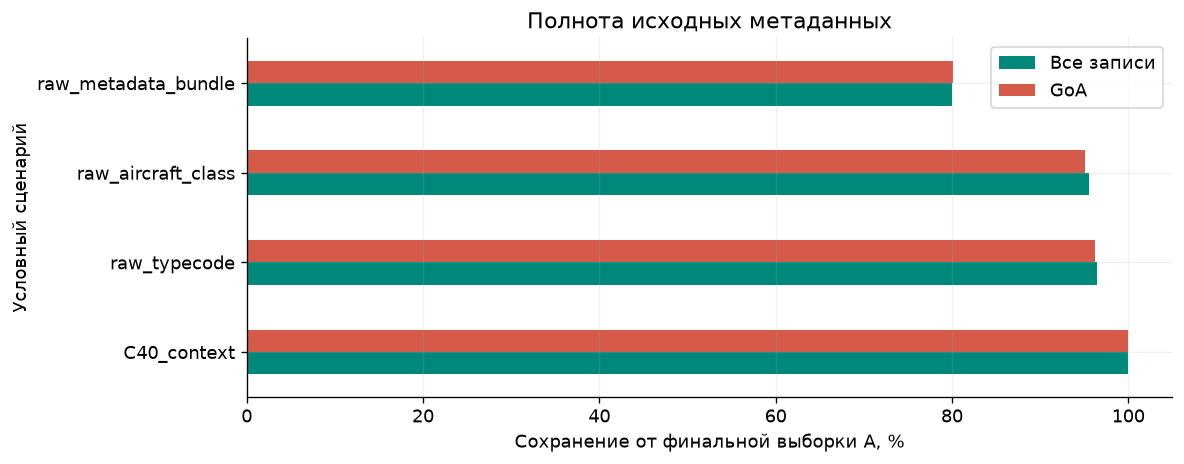

In [3]:
totals={s:[0,0] for s in scenarios}; groups=[]; leads=[]
missing={f:0 for f in reader.schema_arrow.names}
for batch in reader.iter_batches(batch_size=150000):
    d=batch.to_pandas(); y=d.GoA.astype(bool)
    for f in d.columns:
        m=d[f].isna()
        if str(batch.schema.field(f).type)=='string': m=m | d[f].eq('').fillna(False)
        missing[f]+=int(m.sum())
    first=d.attempt_times.map(lambda a: min(a) if a is not None and len(a) else pd.NaT)
    first=pd.to_datetime(first,utc=True)
    minutes=(first-d.C40_CROSS_TIME).dt.total_seconds()/60
    assert minutes.notna().all() and np.isfinite(minutes).all() and (minutes>0).all()
    leads.append(pd.DataFrame({'minutes':minutes.to_numpy(),'goa':y.to_numpy()}))
    month=d.landing_time.dt.strftime('%Y-%m')
    previous=pd.Series(True,index=d.index)
    for scenario,fields in scenarios.items():
        mask=pd.Series(True,index=d.index)
        for f in fields: mask &= d[f].notna() & d[f].ne('').fillna(False)
        assert (~mask | previous).all(); previous=mask
        totals[scenario][0]+=int(mask.sum()); totals[scenario][1]+=int(y[mask].sum())
        for dimension,values in [('airport',d.airport),('month',month)]:
            q=pd.DataFrame({'group':values[mask],'rows':1,'goa':y[mask].astype(int)})
            q=q.groupby('group',dropna=False)[['rows','goa']].sum().reset_index()
            q['dimension']=dimension; q['scenario']=scenario; groups.append(q)
del reader
assert totals['C40_context']==[entry['rows'],18349]
coverage=pd.DataFrame([{'scenario':s,'rows':v[0],'goa':v[1]} for s,v in totals.items()])
coverage['row_retention_pct']=100*coverage.rows/entry['rows']
coverage['goa_retention_pct']=100*coverage.goa/totals['C40_context'][1]
coverage['goa_rate_pct']=100*coverage.goa/coverage.rows
coverage.to_csv(R/'temporal_scenario_coverage.csv',index=False)
grouped=pd.concat(groups).groupby(['dimension','group','scenario'],dropna=False)[['rows','goa']].sum().reset_index()
grouped.to_csv(R/'temporal_group_coverage.csv',index=False)
contract['missing_rows']=contract.field.map(missing)
contract['missing_pct']=100*contract.missing_rows/entry['rows']
contract.to_csv(R/'temporal_field_contract.csv',index=False)
display(coverage.style.format(precision=3))
coverage.set_index('scenario')[['row_retention_pct','goa_retention_pct']].rename(
    columns={'row_retention_pct':'Все записи','goa_retention_pct':'GoA'}).plot.barh(figsize=(10,4),color=['#00897B','#D65A4A'])
plt.xlabel('Сохранение от финальной выборки A, %'); plt.xlim(0,105)
plt.ylabel('Условный сценарий'); plt.title('Полнота исходных метаданных')
save('13_temporal_metadata_coverage')


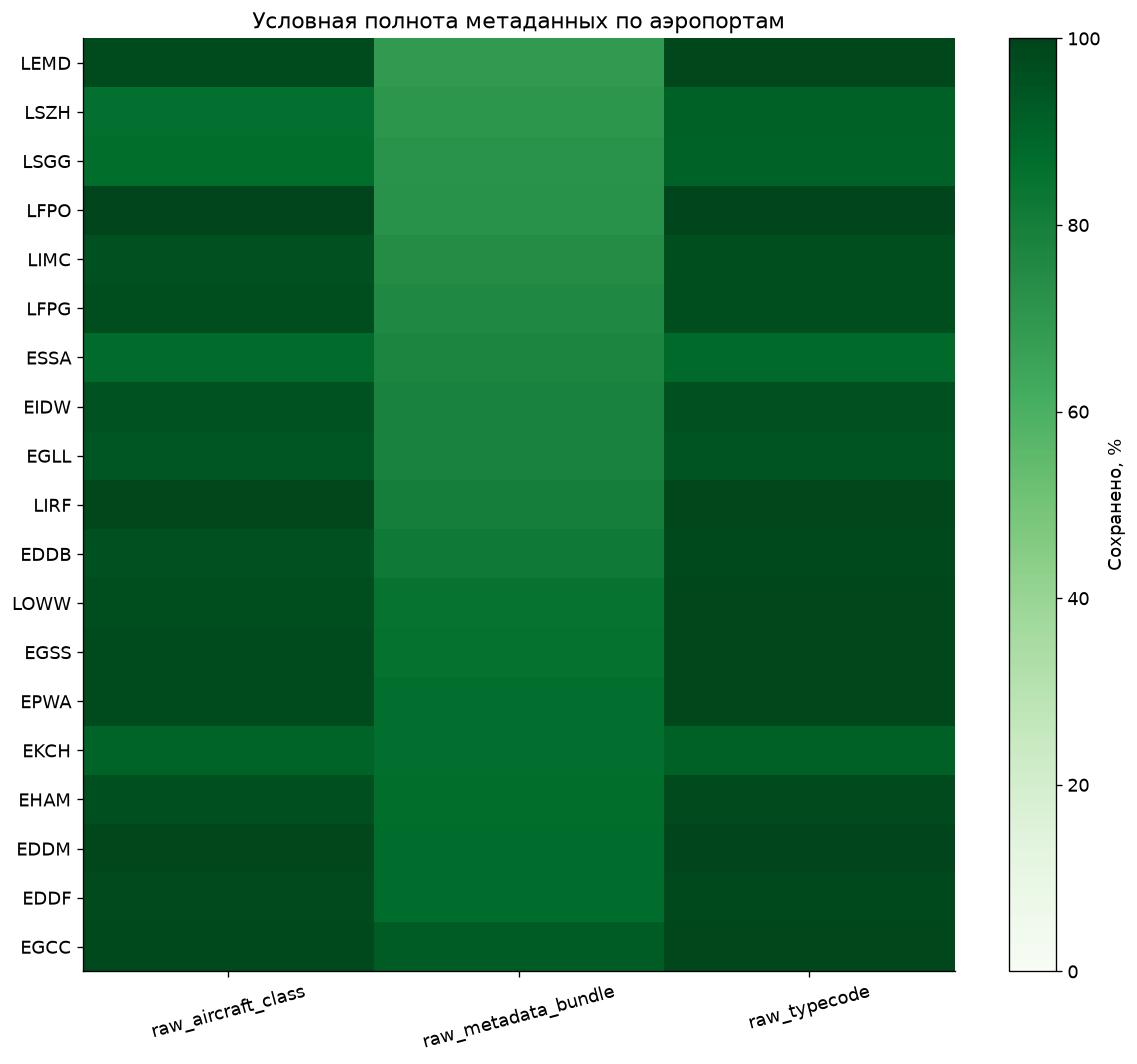

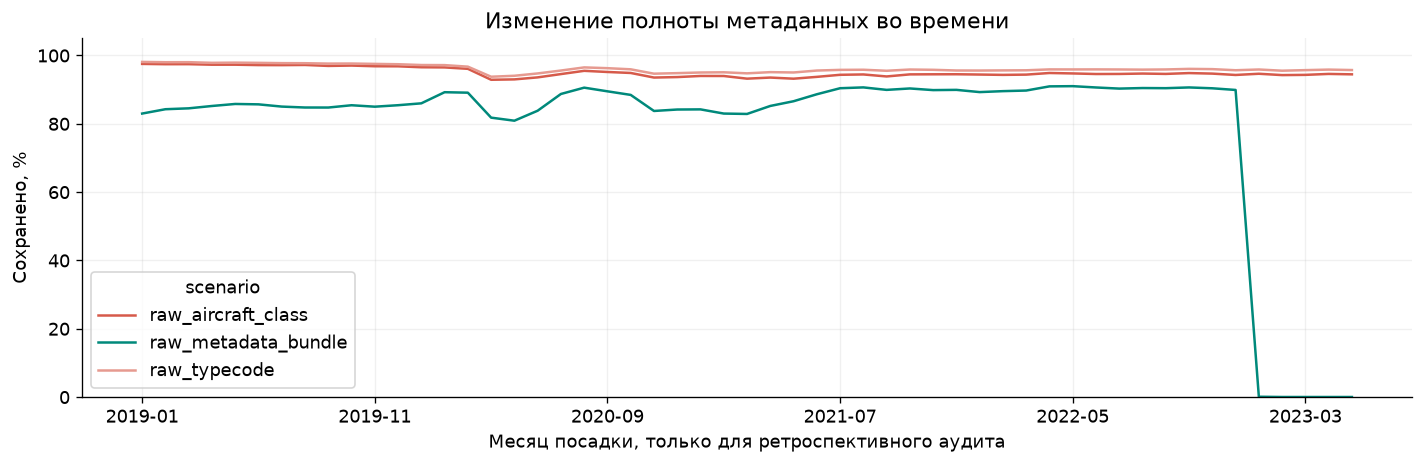

In [4]:
g=grouped[grouped.dimension=='airport'].pivot(index='group',columns='scenario',values='rows').fillna(0)
pct=100*g.div(g.C40_context,axis=0)
pct=pct.sort_values('raw_metadata_bundle').drop(columns='C40_context')
fig,ax=plt.subplots(figsize=(10,9))
im=ax.imshow(pct,aspect='auto',vmin=0,vmax=100,cmap='Greens')
ax.set_yticks(range(len(pct)),pct.index); ax.set_xticks(range(len(pct.columns)),pct.columns,rotation=15)
fig.colorbar(im,ax=ax,label='Сохранено, %'); ax.grid(False)
ax.set_title('Условная полнота метаданных по аэропортам')
save('14_temporal_airport_coverage')
g=grouped[grouped.dimension=='month'].pivot(index='group',columns='scenario',values='rows').fillna(0)
(100*g.div(g.C40_context,axis=0)).drop(columns='C40_context').plot(figsize=(12,4))
plt.ylabel('Сохранено, %'); plt.xlabel('Месяц посадки, только для ретроспективного аудита')
plt.title('Изменение полноты метаданных во времени'); plt.ylim(0,105)
save('15_temporal_month_coverage')


## 3. Запас времени: диагностическое распределение

Разница первого зарегистрированного attempt_times и C40 — ретроспективный
интервал до события из таблицы, не подтвержденный горизонт прогноза до решения
экипажа. Будущий timestamp запрещен как признак. Пороги 5, 10, 15 и 20 минут
выбраны для описания распределения, не как нормативные требования.
Этот раздел условен относительно уже отобранной выборки A.

goa,False,True
quantile,,
0.010000,9.53,8.40
0.050000,10.37,9.78
0.250000,12.08,12.13
0.500000,14.30,14.75
0.750000,17.15,17.93
0.950000,22.02,24.21
0.990000,28.45,32.73


,minimum_minutes,rows,goa
0,0,6331485,18349
1,5,6331383,18348
2,10,6164944,17229
3,15,2743630,8757
4,20,610976,2617


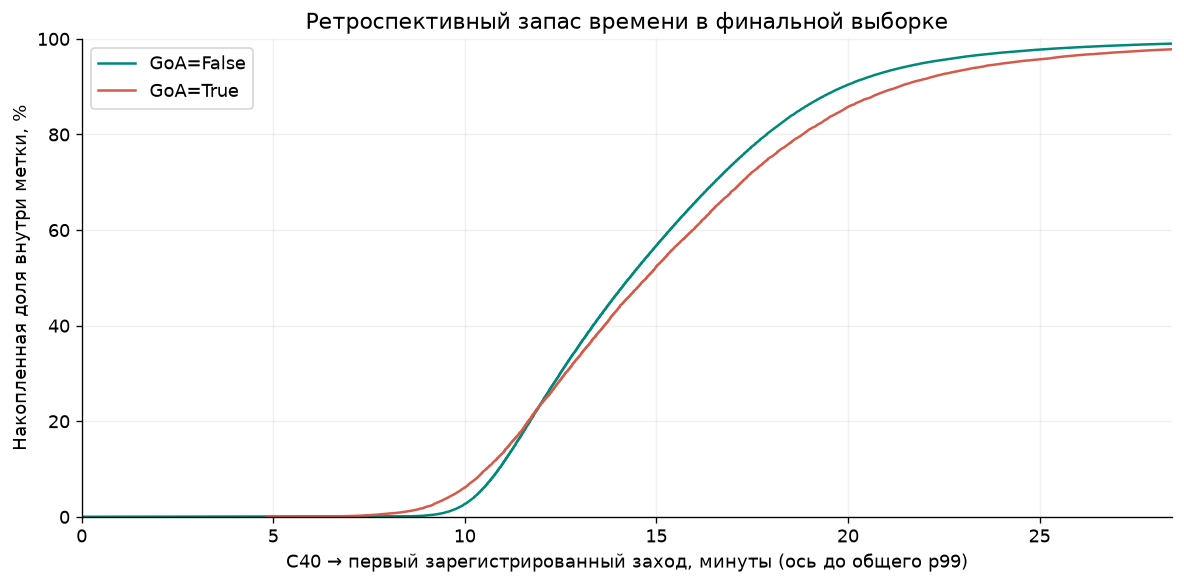

317

In [5]:
lead=pd.concat(leads,ignore_index=True)
quantiles=[]; horizons=[]
for label in [False,True]:
    values=lead.loc[lead.goa.eq(label),'minutes']
    for probability in [.01,.05,.25,.5,.75,.95,.99]:
        quantiles.append({'goa':label,'quantile':probability,'minutes':values.quantile(probability)})
for threshold in [0,5,10,15,20]:
    mask=lead.minutes.ge(threshold)
    horizons.append({'minimum_minutes':threshold,'rows':int(mask.sum()),
                     'goa':int(lead.loc[mask,'goa'].sum())})
quantiles=pd.DataFrame(quantiles); horizons=pd.DataFrame(horizons)
quantiles.to_csv(R/'temporal_lead_quantiles.csv',index=False)
horizons.to_csv(R/'temporal_horizon_coverage.csv',index=False)
display(quantiles.pivot(index='quantile',columns='goa',values='minutes').style.format(precision=2))
display(horizons)
fig,ax=plt.subplots(figsize=(10,5))
for label,color in [(False,'#00897B'),(True,'#D65A4A')]:
    values=np.sort(lead.loc[lead.goa.eq(label),'minutes'].to_numpy())
    # Отображаем эмпирические квантили: не строим миллионы точек.
    probabilities=np.linspace(0,1,1001)
    ax.plot(np.quantile(values,probabilities),probabilities*100,label=f'GoA={label}',color=color)
ax.set_xlim(0,float(lead.minutes.quantile(.99))); ax.set_ylim(0,100)
ax.set_xlabel('C40 → первый зарегистрированный заход, минуты (ось до общего p99)')
ax.set_ylabel('Накопленная доля внутри метки, %'); ax.legend()
ax.set_title('Ретроспективный запас времени в финальной выборке')
save('16_temporal_lead_distribution')
assert sha(DATA)==entry['sha256']
for dimension in ['airport','month']:
    check=grouped[grouped.dimension==dimension].groupby('scenario')[['rows','goa']].sum()
    pd.testing.assert_frame_equal(check.sort_index(),coverage.set_index('scenario')[['rows','goa']].sort_index())
audit={'input_sha256':entry['sha256'],'rows':len(lead),'goa':int(lead.goa.sum()),
       'fields_classified':len(contract),'all_leads_positive':True,
       'group_balances_passed':True,'input_unchanged':True,
       'operational_availability_verified':False,'training_performed':False}
(R/'temporal_verification.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')


## 4. Вывод и следующий проверяемый шаг

Аудит измеряет полноту полей и ретроспективный интервал в финальной выборке.
Он не измеряет доступность сообщений в реальном времени и не оценивает
ухудшение или завышение метрик модели из-за утечки.

Перед моделированием нужно зафиксировать время получения C40, исторические
версии метаданных, определение предполагаемого аэропорта и семантику AP_C_RWY.
Если этих данных нет, исследование остается ретроспективным с явно указанными
предположениями. Восстановленные описания самолетов не подменяют эту проверку.
Для оценки модели далее потребуется временное разделение и контроль повторных
наблюдений по валидированному ключу. Этот ноутбук не запускает такую оценку.